# This code will demonstrate a worked example of SDB in the Canadian Arctic
### It is based on a composite from Sentinel-2, covering the area of chart 7185.

#### 1) Install and import needed packages

In [1]:
!pip install rasterio
!pip install geopandas

In [2]:
import os
import os.path
import math
import glob

import numpy as np

import rasterio
import rasterio.plot
from rasterio.plot import show

import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

import pandas as pd
import geopandas as gpd

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from scipy.stats import pearsonr

import scipy

from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

import warnings
warnings.filterwarnings('ignore')

####2) Setup access to Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

# I put my files in a folder called "7185"
os.chdir("drive/My Drive/7185")

Mounted at /content/drive


#### 3) Read composite image, and plot it to check that it loaded alright

In [5]:
myDir = "C:/Users/ander/OneDrive - University of Ottawa/SDB/Corsica/"
os.chdir(myDir)

# Read image into array
filename = "S2composite_south_clipped.tif"
image = rasterio.open(filename)

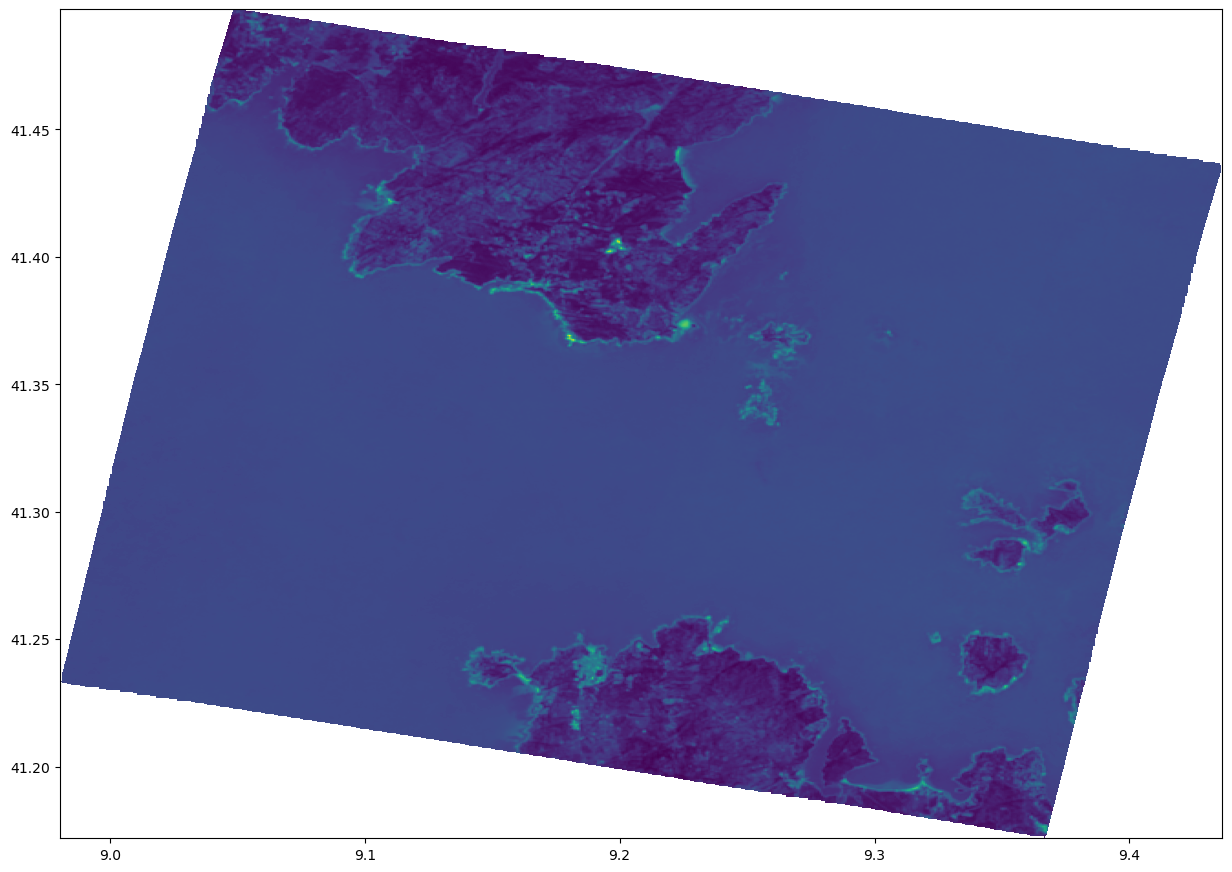

In [6]:
if False:
  fig, ax = plt.subplots()
  fig.set_size_inches(15, 15)
  show(image, ax=ax)

In [7]:
# Convert image bands to numpy arrays for all subsequent processing
b1 = image.read(1)
b2 = image.read(2)
b3 = image.read(3)
b4 = image.read(4)
b5 = image.read(5)

In [44]:
### If we want to display it with its proper colours (not needed for analysis), we need to reorder it with numpy ###
### But the contrast enhancement is tricky ###

if False:
  # Normalize bands into 0.0 - 1.0 scale
  def normalize(array):
      array_min, array_max = np.nanmin(array), np.nanmax(array)
      return (array - array_min).astype(float) / (array_max - array_min).astype(float)

  # Normalize band DN
  red_norm = normalize(red)
  green_norm = normalize(green)
  blue_norm = normalize(blue)

  # Stack bands
  rgb = np.dstack((red_norm, green_norm, blue_norm))
  rgb_v2 = np.rot90(rgb, k=1, axes=(0, 2))
  rgb_v3 = np.rot90(rgb_v2, k=1, axes=(1, 2))
  rgb_v4 = np.flip(rgb_v3, axis=1)

  # Plot it
  fig, ax = plt.subplots()
  fig.set_size_inches(15, 15)
  show(rgb_v4, ax=ax)

#### 4) Load ICESat-2 data

In [45]:
# Read the file
surveydataFile = "icesat_7185_cleaned_GR.shp"
df = gpd.read_file(surveydataFile)

# Clean up a bit
df["group"] = df["group_"]
df["split"] = df["Train_Val_"] 

In [46]:
# Clean up data frame to only contain the necessary information
columnsToRetain = ['depth', 'group', 'split', 'geometry']
df = df.drop(columns=[col for col in df if col not in columnsToRetain])

In [47]:
# Reproject to match imageCRS
imageCRS = image.crs
surveyCRS = df.crs

if surveyCRS != imageCRS:
    df  = df.to_crs(imageCRS)

#### 5) Sample image bands using points from shapefiles

In [11]:
coords = [(x,y) for x, y in zip(df['geometry'].x, df['geometry'].y)]
df['b1'] = [x[0] for x in image.sample(coords, indexes=1)]
df['b2'] = [x[0] for x in image.sample(coords, indexes=2)]
df['b3'] = [x[0] for x in image.sample(coords, indexes=3)]
df['b4'] = [x[0] for x in image.sample(coords, indexes=4)]
df['b5'] = [x[0] for x in image.sample(coords, indexes=5)]

In [12]:
# Retain mean depth values when there are multiple points in each pixel
df['x'] = df.geometry.x
df['y'] = df.geometry.y

df = df.groupby(['b1', 'b2', 'b3', 'b4', 'b5']).mean().reset_index()

In [13]:
# Convert group back into integer
df['group'] = df['group'].astype(int)

#### 6) OPTIONAL: Do SDB  using Stumpf's method

OLS regression equation is: Depth = 104.65127 * log_ratio + -108.05236
Pearson's correlation: 0.845


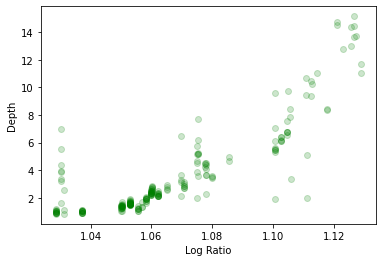

In [ ]:
if False:
  # Calculate log ratio
  n = 1000
  surveydata["log_blue"] = np.log(n * surveydata["blue"])
  surveydata["log_green"] = np.log(n * surveydata["green"])
  surveydata["log_ratio"] = surveydata["log_blue"] / surveydata["log_green"]

  # Plot and do stats
  y = surveydata['depth'].to_numpy()
  x = surveydata['log_ratio'].to_numpy()

  # Need to do this reshape thing for the regression functions to read the data properly 
  Y = y.reshape(-1, 1)  
  X = x.reshape(-1, 1)

  reg = LinearRegression()
  reg.fit(X, Y)
  OLS_slope = float("{:.5f}".format(reg.coef_[0][0]))
  OLS_intercept = float("{:.5f}".format(reg.intercept_[0]))
  print ("OLS regression equation is: Depth = " + str(OLS_slope) + " * log_ratio + " + str(OLS_intercept))

  corr, _ = pearsonr(y, x)
  print("Pearson's correlation: %.3f" % corr)

  plt.scatter(x, y, c="g", alpha=0.2)
  #plt.plot(x, OLS_intercept + OLS_slope * x, 'r-', label="OLS")
  plt.xlabel("Log Ratio")
  plt.ylabel("Depth")
  plt.show()

#### 7) Do SDB with Random Forest

In [21]:
# Split data into cal, val, and test
cal = df[df['split'] == 1]  # 704
val = df[df['split'] == 2]  # 221
test = df[df['split'] == 3]  # 157
calval = df[df['split'] != 3]  # 925

In [19]:
# Optimize hyperparameters to minimize MAE for val

n_estimators = [30, 100, 300, 1000]
# max_features = ["auto", "sqrt", "log2"]  Disabling this because much testing reveals auto is always best anyway
max_features = ['auto']
criterion = "absolute_error"
columns = ["depth", "pred"]

best_n_estimators = n_estimators[0]
best_max_features = max_features[0]
best_mae = 1000000

for estimators in n_estimators:
  for features in max_features:
  
    # Set up calibration data
    X = np.dstack((cal["b1"], cal["b2"], cal["b3"], cal["b4"], cal["b5"]))[0, :, :]
    y = cal["depth"]

    # Train model on calibration data
    reg = RandomForestRegressor(n_estimators=estimators, max_features=features, criterion=criterion)  # Using default values for everything else
    reg.fit(X, y)

    # Make predictions for validation data
    newX = np.dstack((val["b1"], val["b2"], val["b3"], val["b4"], val["b5"]))[0, :, :]
    newy = val["depth"]
    pred = reg.predict(newX)

    mae = np.mean(np.abs(newy  - pred))
    print("n_estimators: " + str(estimators) + "; max_features: " + features + "; MAE: " + str(mae))

    if mae < best_mae:
      best_mae = mae
      best_n_estimators = estimators
      best_max_features = features

n_estimators: 30; max_features: auto; MAE: 1.217760646949578
n_estimators: 100; max_features: auto; MAE: 1.1976879688116242
n_estimators: 300; max_features: auto; MAE: 1.2021904593919952
n_estimators: 1000; max_features: auto; MAE: 1.1855231483803974


In [20]:
print("Based on these results we will proceed with " + str(best_n_estimators) + " estimators, and " + best_max_features + " features")

Based on these results we will proceed with 1000 estimators, and auto features


In [22]:
# Calibrate final model
X = np.dstack((calval["b1"], calval["b2"], calval["b3"], calval["b4"], calval["b5"]))[0, :, :]
y = calval["depth"]

reg = RandomForestRegressor(n_estimators=best_n_estimators, max_features=best_max_features, criterion=criterion)
reg.fit(X, y)

newX = np.dstack((test["b1"], test["b2"], test["b3"], test["b4"], test["b5"]))[0, :, :]
test["pred"] = reg.predict(newX)

Pearson's correlation: 0.966
Random Forest MAE: 0.86


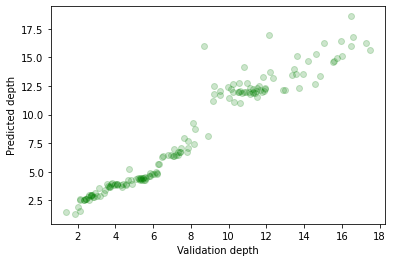

In [23]:
# Plot and do stats
corr, _ = pearsonr(test["pred"], test["depth"])
print("Pearson's correlation: %.3f" % corr)

test["error"] = test["pred"] - test["depth"]
test["abs_error"] = np.abs(test["error"])
mae_total = np.mean(test["abs_error"])

print("Random Forest MAE: %.2f" % mae_total)

plt.scatter(test["depth"], test["pred"], c="g", alpha=0.2)
plt.xlabel("Validation depth")
plt.ylabel("Predicted depth")
plt.show()

In [24]:
# Disaggregate error stats by depth range
min_depth = test['pred'].min()
max_depth = test['pred'].max()
min_depth_rounded = int(np.floor(min_depth))
max_depth_rounded = int(np.ceil(max_depth))

# Lists to hold results
mindepth = [] # This will hold the lower bound depth value of the interval
maxdepth = [] # Same, upper bound
mae = [] # MAE for the interval

for j in range(min_depth_rounded, max_depth_rounded, 1):
  
  df = test[test['pred'].between(j, j+1, inclusive=True)]

  errors = (df['depth'] - df['pred']).tolist()
  meanabserror = np.mean(np.abs(errors))

  mindepth.append(j)
  maxdepth.append(j+1)
  mae.append(meanabserror)

  # Print all results to a text file
results_df = pd.DataFrame(
    {'mindepth': mindepth,
    'maxdepth': maxdepth,
    'mae': mae})

filename_mae = os.path.splitext(filename)[0] + "_mae_GR.txt"
results_df.to_csv(filename_mae, index=False)
f = open(filename_mae, 'a')
f.write('MAE across all points: ' + str(mae_total))
f.close()

#### 8) Add more information to the predictors, from smoothed images, then redo 7)

In [33]:
# Reload data
surveydataFile = "icesat_7185_cleaned_GR.shp"
df = gpd.read_file(surveydataFile)

# Clean up a bit
df["group"] = df["group_"]
df["split"] = df["Train_Val_"]

# Clean up data frame to only contain the necessary information
columnsToRetain = ['depth', 'group', 'split', 'geometry']
df = df.drop(columns=[col for col in df if col not in columnsToRetain])

# Reproject to match imageCRS
imageCRS = image.crs
surveyCRS = df.crs
if surveyCRS != imageCRS:
    df  = df.to_crs(imageCRS)

coords = [(x,y) for x, y in zip(df['geometry'].x, df['geometry'].y)]
df['b1'] = [x[0] for x in image.sample(coords, indexes=1)]
df['b2'] = [x[0] for x in image.sample(coords, indexes=2)]
df['b3'] = [x[0] for x in image.sample(coords, indexes=3)]
df['b4'] = [x[0] for x in image.sample(coords, indexes=4)]
df['b5'] = [x[0] for x in image.sample(coords, indexes=5)]

# Retain mean depth values when there are multiple points in each pixel
df['x'] = df.geometry.x
df['y'] = df.geometry.y

df = df.groupby(['b1', 'b2', 'b3', 'b4', 'b5']).mean().reset_index()

# Convert group back into integer
df['group'] = df['group'].astype(int)

In [34]:
windowsizes = [3, 5, 7, 9]
#windowsizes = [3]
n_estimators = [30, 100, 300, 1000]
# max_features = ["auto", "sqrt", "log2"]  Disabling this because much testing reveals auto is always best anyway
max_features = ['auto']
criterion = "absolute_error"
columns = ["depth", "pred"]

best_mae = 1000000
best_windowsize = windowsizes[0]
best_n_estimators = n_estimators[0]
best_max_features = max_features[0]

df = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.x, df.y))
coords = [(x,y) for x, y in zip(df['geometry'].x, df['geometry'].y)]

for windowsize in windowsizes:

  # Run median filters on each band
  b1_smooth = scipy.ndimage.median_filter(b1, size=windowsize)
  b2_smooth = scipy.ndimage.median_filter(b2, size=windowsize)
  b3_smooth = scipy.ndimage.median_filter(b3, size=windowsize)
  b4_smooth = scipy.ndimage.median_filter(b4, size=windowsize)
  b5_smooth = scipy.ndimage.median_filter(b5, size=windowsize)

  # Save to new file
  filename_smooth = os.path.splitext(filename)[0] + "_smooth_" + str(windowsize) + "_GR.tif"
  if not os.path.isfile(filename_smooth): 
    with rasterio.open(filename_smooth, 'w', driver='GTiff',
                      height=image.height, width=image.width,
                      count=5, dtype='float32',
                      crs=image.crs, transform=image.transform) as dst:
        dst.write(b1_smooth, 1)
        dst.set_band_description(1, 'b1_smooth')
        dst.write(b2_smooth, 2)
        dst.set_band_description(2, 'b2_smooth')
        dst.write(b3_smooth, 3)
        dst.set_band_description(3, 'b3_smooth')
        dst.write(b4_smooth, 4)
        dst.set_band_description(4, 'b4_smooth')
        dst.write(b5_smooth, 5)
        dst.set_band_description(5, 'b5_smooth')

  # Read the new file
  image_smooth = rasterio.open(filename_smooth)

  # Sample the new data points
  df['b1_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=1)]
  df['b2_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=2)]
  df['b3_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=3)]
  df['b4_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=4)]
  df['b5_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=5)]

  # Split data into cal, val, and test
  cal = df[df['split'] == 1]  # 704
  val = df[df['split'] == 2]  # 221
  test = df[df['split'] == 3]  # 157
  calval = df[df['split'] != 3]  # 925

  for estimators in n_estimators:
    for features in max_features:
  
      X = np.dstack((cal["b1"], cal["b2"], cal["b3"], cal["b4"], cal["b5"], cal["b1_smooth"], 
                    cal["b2_smooth"], cal["b3_smooth"], cal["b4_smooth"], cal["b5_smooth"]))[0, :, :]
      y = cal["depth"]

      reg = RandomForestRegressor(n_estimators=estimators, max_features=features, criterion=criterion)  # Using default values for everything else
      reg.fit(X, y)

      newX = np.dstack((val["b1"], val["b2"], val["b3"], val["b4"], val["b5"], val["b1_smooth"],
                        val["b2_smooth"], val["b3_smooth"], val["b4_smooth"], val["b5_smooth"]))[0, :, :]
      newy = val["depth"]
      pred = reg.predict(newX)

      mae = np.mean(np.abs(newy  - pred))
      print("windowsize: " + str(windowsize) + "; n_estimators: " + str(estimators) + "; max_features: " + features + "; MAE: " + str(mae))

      if mae < best_mae:
        best_mae = mae
        best_n_estimators = estimators
        best_max_features = features
        best_windowsize = windowsize

windowsize: 3; n_estimators: 30; max_features: auto; MAE: 1.1692165843316604
windowsize: 3; n_estimators: 100; max_features: auto; MAE: 1.079521769266508
windowsize: 3; n_estimators: 300; max_features: auto; MAE: 1.1183247472133215
windowsize: 3; n_estimators: 1000; max_features: auto; MAE: 1.1301971534864244
windowsize: 5; n_estimators: 30; max_features: auto; MAE: 1.133398123813008
windowsize: 5; n_estimators: 100; max_features: auto; MAE: 1.143092810000839
windowsize: 5; n_estimators: 300; max_features: auto; MAE: 1.14401896245758
windowsize: 5; n_estimators: 1000; max_features: auto; MAE: 1.1406052312310901
windowsize: 7; n_estimators: 30; max_features: auto; MAE: 1.2390632807393145
windowsize: 7; n_estimators: 100; max_features: auto; MAE: 1.1847869932237156
windowsize: 7; n_estimators: 300; max_features: auto; MAE: 1.1969795161420058
windowsize: 7; n_estimators: 1000; max_features: auto; MAE: 1.1685509531996938
windowsize: 9; n_estimators: 30; max_features: auto; MAE: 1.221598354

In [35]:
print("Based on these results we will proceed with " + str(best_windowsize) + " windowsize, and " + str(best_n_estimators) + " estimators, and " + best_max_features + " features")

Based on these results we will proceed with 3 windowsize, and 100 estimators, and auto features


In [36]:
# Set filename_smooth
filename_smooth = os.path.splitext(filename)[0] + "_smooth_" + str(best_windowsize) + "_GR.tif"

 # Read the new file
image_smooth = rasterio.open(filename_smooth)

# Sample the new data points
df['b1_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=1)]
df['b2_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=2)]
df['b3_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=3)]
df['b4_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=4)]
df['b5_smooth'] = [x[0] for x in image_smooth.sample(coords, indexes=5)]

In [37]:
# Calibrate final model
X = np.dstack((calval["b1"], calval["b2"], calval["b3"], calval["b4"], calval["b5"],
               calval["b1_smooth"], calval["b2_smooth"], calval["b3_smooth"], calval["b4_smooth"], calval["b5_smooth"]))[0, :, :]
y = calval["depth"]

reg = RandomForestRegressor(n_estimators=best_n_estimators, max_features=best_max_features, criterion=criterion)
reg.fit(X, y)

newX = np.dstack((test["b1"], test["b2"], test["b3"], test["b4"], test["b5"],
                  test["b1_smooth"], test["b2_smooth"], test["b3_smooth"], test["b4_smooth"], test["b5_smooth"]))[0, :, :]
test["pred"] = reg.predict(newX)

Pearson's correlation: 0.984
Random Forest MAE: 0.62


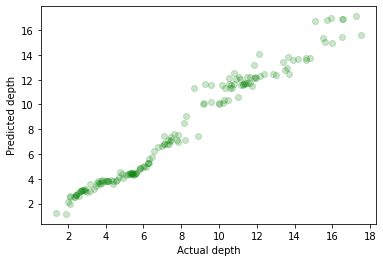

In [40]:
# Plot and do stats
corr, _ = pearsonr(test["pred"], test["depth"])
print("Pearson's correlation: %.3f" % corr)

test["error"] = test["pred"] - test["depth"]
test["abs_error"] = np.abs(test["error"])
mae_total = np.mean(test["abs_error"])

print("Random Forest MAE: %.2f" % mae_total)

plt.scatter(test["depth"], test["pred"], c="g", alpha=0.2)
plt.xlabel("Actual depth")
plt.ylabel("Predicted depth")
plt.show()

In [39]:
# Disaggregate error stats by depth range
min_depth = test['pred'].min()
max_depth = test['pred'].max()
min_depth_rounded = int(np.floor(min_depth))
max_depth_rounded = int(np.ceil(max_depth))

# Lists to hold results
mindepth = [] # This will hold the lower bound depth value of the interval
maxdepth = [] # Same, upper bound
mae = [] # MAE for the interval

for j in range(min_depth_rounded, max_depth_rounded, 1):
  
  df = test[test['pred'].between(j, j+1, inclusive=True)]

  errors = (df['depth'] - df['pred']).tolist()
  meanabserror = np.mean(np.abs(errors))

  mindepth.append(j)
  maxdepth.append(j+1)
  mae.append(meanabserror)

  # Print all results to a text file
results_df = pd.DataFrame(
    {'mindepth': mindepth,
    'maxdepth': maxdepth,
    'mae': mae})

filename_mae = os.path.splitext(filename)[0] + "_" + str(best_windowsize) + "_mae_GR.txt"
results_df.to_csv(filename_mae, index=False)
f = open(filename_mae, 'a')
f.write('MAE across all points: ' + str(mae_total))
f.close()

#### 9) OPTIONAL: Improve the statistics to be disaggregated by group, by depth intervals, and use 95% CI in addition to MAE

In [ ]:
# First create an empty data frame to hold the results
rf_results = pd.DataFrame(columns=surveydata.columns)

# Group values
groupValues = surveydata.group.unique()

for i in groupValues:
  train = surveydata[surveydata["group"] != i]
  test = surveydata[surveydata["group"] == i]

  X = np.dstack((train["coastal"], train["blue"], train["green"], train["red"],
                  train["nir"], train["coastal_smooth"], train["blue_smooth"],
                  train["green_smooth"], train["red_smooth"], train["nir_smooth"]))[0, :, :]
  y = train["depth"]

  # Train RF model
  reg = RandomForestRegressor()  # Using default values for everything
  reg.fit(X, y)

  # Make predictions
  newX = np.dstack((test["coastal"], test["blue"], test["green"], test["red"],
                test["nir"], test["coastal_smooth"], test["blue_smooth"],
                test["green_smooth"], test["red_smooth"], test["nir_smooth"]))[0, :, :]
  test["rf_predicted_smooth_hoo"] = reg.predict(newX)

  # Save predictions in results data frame
  rf_results = rf_results.append(test)

In [ ]:
allResults = []

for i in groupValues:

  df = rf_results[rf_results["group"] == i]

  mae_alldepths = np.mean(np.abs(df["depth"] - df["rf_predicted_smooth_hoo"].tolist()))

  # Calculate 95% CI for each predicted depth range
  min_depth = df['rf_predicted_smooth_hoo'].min()
  max_depth = df['rf_predicted_smooth_hoo'].max()
  min_depth_rounded = int(np.floor(min_depth))
  max_depth_rounded = int(np.ceil(max_depth))

  # Lists to hold results
  mindepth = [] # This will hold the lower bound depth value of the interval
  maxdepth = [] # Same, upper bound
  p5 = [] # The 5th percentile of errors for the interval
  p95 = [] # Same, but 95th percentile
  mae = [] # MAE for the interval

  for j in range(min_depth_rounded, max_depth_rounded, 1):
    
    df2 = df[df['rf_predicted_smooth_hoo'].between(j, j+1, inclusive=True)]

    errors = (df2['depth'] - df2['rf_predicted_smooth_hoo']).tolist()
    if len(errors) > 0:
      low = np.percentile(errors, 5)
      high = np.percentile(errors, 95)
    else:
      low = float("nan")
      high = float("nan")
    meanabserror = np.mean(np.abs(errors))

    mindepth.append(j)
    maxdepth.append(j+1)
    p5.append(low)
    p95.append(high)
    mae.append(meanabserror)

    # Print all results to a text file
  results_df = pd.DataFrame(
      {'mindepth': mindepth,
      'maxdepth': maxdepth,
      'p5': p5,
      'p95': p95,
      'mae': mae
      })

  filename_unc = os.path.splitext(filename)[0] + "_group_" + str(i) + "_uncertainty.csv"
  results_df.to_csv(filename_unc)

  filename_mae = os.path.splitext(filename)[0] + "_group_" + str(i) + "_mae.txt"
  with open(filename_mae, 'w') as f:
      f.write(str(mae_alldepths))

#### 10) Now make mapped predictions

In [ ]:
# To work with predictions, we need to flatten the input arrays
# Exports from GEE can contain nan values in the corners, turn those into zeros

coastal_flat = np.nan_to_num(coastal.flatten())
blue_flat = np.nan_to_num(blue.flatten())
green_flat = np.nan_to_num(green.flatten())
red_flat = np.nan_to_num(red.flatten())
nir_flat = np.nan_to_num(nir.flatten())

coastal_smooth_flat = np.nan_to_num(coastal_smooth.flatten())
blue_smooth_flat = np.nan_to_num(blue_smooth.flatten())
green_smooth_flat = np.nan_to_num(green_smooth.flatten())
red_smooth_flat = np.nan_to_num(red_smooth.flatten())
nir_smooth_flat = np.nan_to_num(nir_smooth.flatten())

newXraster = np.dstack((coastal_flat, blue_flat, green_flat, red_flat,
                        nir_flat, coastal_smooth_flat, blue_smooth_flat,
                        green_smooth_flat, red_smooth_flat, nir_smooth_flat))[0, :, :]

raster_predictions = reg.predict(newXraster)

raster_predictions_unflattened = raster_predictions.reshape(red.shape)

In [ ]:
# Find lower and upper bounds for each pixel
lowerbounds = np.copy(raster_predictions_unflattened)
upperbounds = np.copy(raster_predictions_unflattened)

In [ ]:
for i in range(min_depth_rounded, max_depth_rounded, 1):
  low = results_df.loc[results_df['mindepth'] == i, 'p5'].iloc[0]
  high = results_df.loc[results_df['mindepth'] == i, 'p95'].iloc[0]
  lowerbounds = np.where((raster_predictions_unflattened >= i) & (raster_predictions_unflattened < i+1), low, lowerbounds)
  upperbounds = np.where((raster_predictions_unflattened >= i) & (raster_predictions_unflattened < i+1), high, upperbounds)

lowerbounds = lowerbounds + raster_predictions_unflattened
upperbounds = upperbounds + raster_predictions_unflattened

In [ ]:
# Write predictions to file
predictionsFilename = "RFpredictions_7193_unc.tif"

# Write to file
with rasterio.Env():

    # Write an array as a raster band to a new file. For the new file's profile, we start with the profile of the source
    profile = image.profile

    # And then change the band count to 3, set the dtype, and specify LZW compression.
    profile.update(
        driver='GTiff',
        dtype=rasterio.float32,
        count=3,
        compress='lzw')

    with rasterio.open(predictionsFilename, 'w', **profile) as dst:
        dst.write(raster_predictions_unflattened.astype(rasterio.float32), 1)
        dst.set_band_description(1, 'Prediction')
        dst.write(lowerbounds.astype(rasterio.float32), 2)
        dst.set_band_description(2, 'LowerBound')
        dst.write(upperbounds.astype(rasterio.float32), 3)
        dst.set_band_description(3, 'UpperBound')